# Part E: KNN Hyperparameter Optimisation


## 1. Environment Setup & Library Ingestion


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time
from IPython.display import display

from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix, classification_report
)

# Styling configuration
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 10
print("Environment and optimization libraries initialized successfully.")

Environment and optimization libraries initialized successfully.


## 2. Preprocessed Data Ingestion & Partition Verification


In [2]:
# Ingest preprocessed splits
df_train = pd.read_csv('credit_train_preprocessed.csv')
df_test = pd.read_csv('credit_test_preprocessed.csv')

# Separate feature matrices and target vectors
X_train = df_train.drop(columns=['dpnm'])
y_train = df_train['dpnm']

X_test = df_test.drop(columns=['dpnm'])
y_test = df_test['dpnm']

print("=== DATASET PARTITION AUDIT ===")
print(f"Training Features Matrix (X_train): {X_train.shape[0]:,} rows x {X_train.shape[1]} features")
print(f"Training Target (y_train balance):  {y_train.value_counts().to_dict()} (50:50 Balanced)")
print(f"Testing Features Matrix (X_test):   {X_test.shape[0]:,} rows x {X_test.shape[1]} features")
print(f"Testing Target (y_test balance):    {y_test.value_counts().to_dict()} (Authentic Unbalanced Test Set)")

=== DATASET PARTITION AUDIT ===
Training Features Matrix (X_train): 37,336 rows x 30 features
Training Target (y_train balance):  {0: 18668, 1: 18668} (50:50 Balanced)
Testing Features Matrix (X_test):   5,993 rows x 30 features
Testing Target (y_test balance):    {0: 4667, 1: 1326} (Authentic Unbalanced Test Set)


## 3. Baseline Model Benchmark Snapshot (Part D Reference)


In [3]:
# Instantiate baseline model from Part D
knn_base = KNeighborsClassifier(
    n_neighbors=5,
    weights='uniform',
    metric='minkowski',
    p=2,
    n_jobs=-1
)

start_base_train = time.time()
knn_base.fit(X_train, y_train)
base_train_time = time.time() - start_base_train

start_base_infer = time.time()
base_preds = knn_base.predict(X_test)
base_probs = knn_base.predict_proba(X_test)[:, 1]
base_infer_time = time.time() - start_base_infer

# Baseline metrics
base_acc = accuracy_score(y_test, base_preds)
base_prec = precision_score(y_test, base_preds)
base_rec = recall_score(y_test, base_preds)
base_f1 = f1_score(y_test, base_preds)
base_auc = roc_auc_score(y_test, base_probs)

baseline_summary = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision (Default)', 'Recall (Default)', 'F1-Score', 'ROC-AUC', 'Fit Time (s)', 'Inference Time (s)'],
    'Part D Baseline Score': [
        f"{base_acc:.4f}", f"{base_prec:.4f}", f"{base_rec:.4f}",
        f"{base_f1:.4f}", f"{base_auc:.4f}", f"{base_train_time:.4f}", f"{base_infer_time:.4f}"
    ]
})

print("=== PART D BASELINE BENCHMARK ESTABLISHED ===")
display(baseline_summary)

=== PART D BASELINE BENCHMARK ESTABLISHED ===


,Metric,Part D Baseline Score
0,Accuracy,0.6508
1,Precision (Default),0.3407
2,Recall (Default),0.6184
3,F1-Score,0.4393
4,ROC-AUC,0.6834
5,Fit Time (s),0.1235
6,Inference Time (s),0.7576


## 4. Hyperparameter Search Space Formulation


In [4]:
# Define hyperparameter grid
param_grid = {
    'n_neighbors': [3, 5, 7, 9, 11, 15, 21, 25],
    'weights': ['uniform', 'distance'],
    'metric': ['euclidean', 'manhattan']
}

# Total candidate evaluations
n_candidates = len(param_grid['n_neighbors']) * len(param_grid['weights']) * len(param_grid['metric'])
print(f"Hyperparameter Search Grid Configured:")
print(f"  • Candidate Configurations: {n_candidates} combinations")
print(f"  • Cross-Validation Strategy: Stratified 3-Fold CV ({n_candidates * 3} total fits)")
print(f"  • Primary Optimization Metric: ROC-AUC (Sensitivity / Specificity Ranking)")

Hyperparameter Search Grid Configured:
  • Candidate Configurations: 32 combinations
  • Cross-Validation Strategy: Stratified 3-Fold CV (96 total fits)
  • Primary Optimization Metric: ROC-AUC (Sensitivity / Specificity Ranking)


## 5. Systematic Hyperparameter Search Execution via GridSearchCV


In [5]:
# Configure Stratified K-Fold
cv_strategy = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

# Instantiate GridSearchCV
knn_estimator = KNeighborsClassifier(n_jobs=-1)
grid_search = GridSearchCV(
    estimator=knn_estimator,
    param_grid=param_grid,
    scoring='roc_auc',
    cv=cv_strategy,
    n_jobs=-1,
    return_train_score=True,
    verbose=1
)

print("Commencing GridSearchCV optimization across 37,336 training instances...")
start_grid = time.time()
grid_search.fit(X_train, y_train)
grid_duration = time.time() - start_grid

print(f"\nGridSearchCV Completed in {grid_duration:.2f} seconds ({grid_duration/60:.2f} minutes).")
print(f"Optimal Hyperparameters Identified: {grid_search.best_params_}")
print(f"Peak Cross-Validated ROC-AUC Score: {grid_search.best_score_:.4f}")

Commencing GridSearchCV optimization across 37,336 training instances...
Fitting 3 folds for each of 32 candidates, totalling 96 fits

GridSearchCV Completed in 190.56 seconds (3.18 minutes).
Optimal Hyperparameters Identified: {'metric': 'manhattan', 'n_neighbors': 5, 'weights': 'distance'}
Peak Cross-Validated ROC-AUC Score: 0.9040


## 6. Empirical Analysis of Search Results & Hyperparameter Surfaces


In [6]:
# Convert cv_results_ to DataFrame
cv_results_df = pd.DataFrame(grid_search.cv_results_)

# Clean and sort top results
cv_summary = cv_results_df[[
    'param_n_neighbors', 'param_weights', 'param_metric',
    'mean_test_score', 'std_test_score', 'mean_train_score', 'rank_test_score'
]].sort_values(by='rank_test_score').reset_index(drop=True)

cv_summary.columns = [
    'k (n_neighbors)', 'Weights', 'Metric',
    'Mean CV ROC-AUC', 'Std CV ROC-AUC', 'Mean Train ROC-AUC', 'Rank'
]

print("=== TOP 10 HYPERPARAMETER CONFIGURATIONS (BY CV ROC-AUC) ===")
display(cv_summary.head(10))

=== TOP 10 HYPERPARAMETER CONFIGURATIONS (BY CV ROC-AUC) ===


,k (n_neighbors),Weights,Metric,Mean CV ROC-AUC,Std CV ROC-AUC,Mean Train ROC-AUC,Rank
0,5,distance,manhattan,0.903969,0.004818,1.0,1
1,7,distance,manhattan,0.902901,0.004130,1.0,2
2,9,distance,manhattan,0.900109,0.003242,1.0,3
3,11,distance,manhattan,0.896154,0.002985,1.0,4
4,3,distance,manhattan,0.894341,0.002178,1.0,5
5,7,distance,euclidean,0.894151,0.004541,1.0,6
6,5,distance,euclidean,0.893378,0.004402,1.0,7
7,9,distance,euclidean,0.891293,0.005173,1.0,8
8,15,distance,manhattan,0.888713,0.002563,1.0,9
9,11,distance,euclidean,0.887901,0.004549,1.0,10


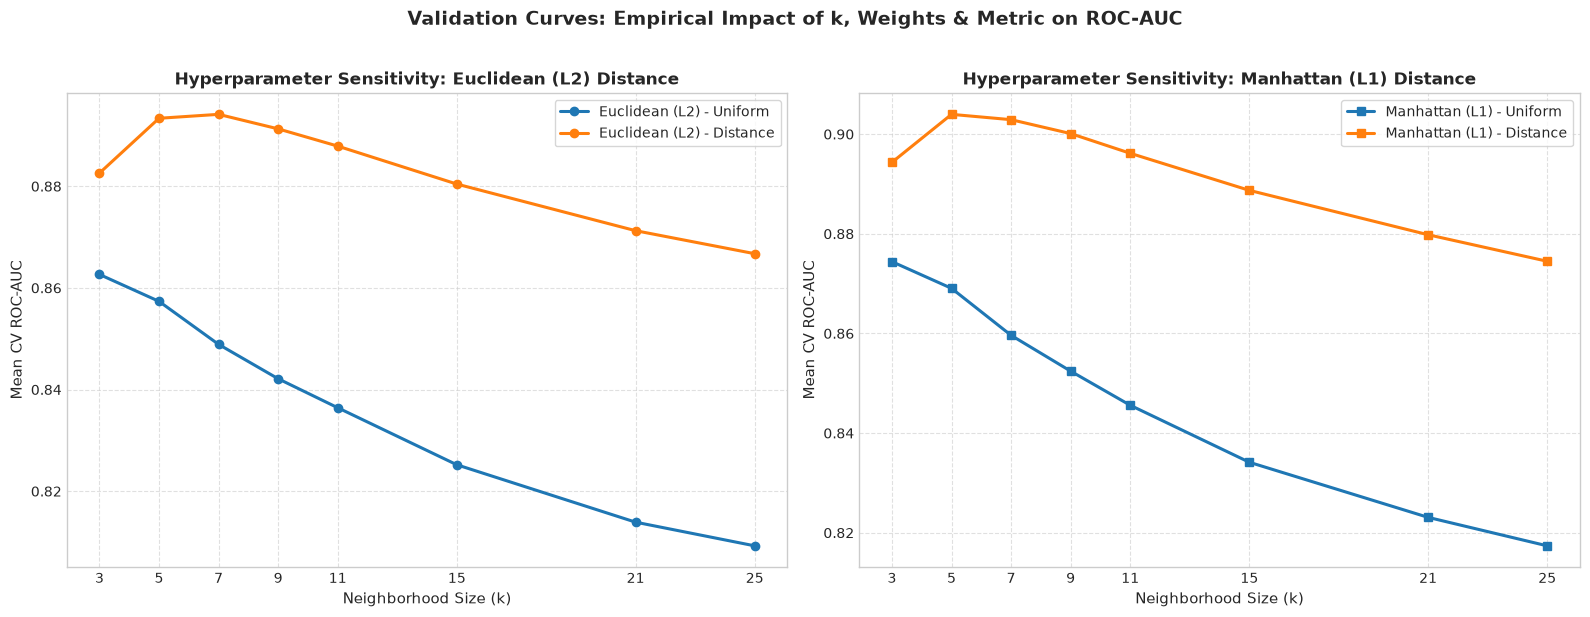

In [7]:
# Plot Validation Curves: k vs Mean CV ROC-AUC
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Subplot 1: Euclidean Distance
for weight in ['uniform', 'distance']:
    subset = cv_summary[(cv_summary['Metric'] == 'euclidean') & (cv_summary['Weights'] == weight)]
    subset = subset.sort_values(by='k (n_neighbors)')
    axes[0].plot(
        subset['k (n_neighbors)'], subset['Mean CV ROC-AUC'],
        marker='o', lw=2.2, label=f"Euclidean (L2) - {weight.capitalize()}"
    )
axes[0].set_title("Hyperparameter Sensitivity: Euclidean (L2) Distance", fontsize=12, weight='bold')
axes[0].set_xlabel("Neighborhood Size (k)", fontsize=11)
axes[0].set_ylabel("Mean CV ROC-AUC", fontsize=11)
axes[0].set_xticks(param_grid['n_neighbors'])
axes[0].legend(frameon=True)
axes[0].grid(True, linestyle='--', alpha=0.6)

# Subplot 2: Manhattan Distance
for weight in ['uniform', 'distance']:
    subset = cv_summary[(cv_summary['Metric'] == 'manhattan') & (cv_summary['Weights'] == weight)]
    subset = subset.sort_values(by='k (n_neighbors)')
    axes[1].plot(
        subset['k (n_neighbors)'], subset['Mean CV ROC-AUC'],
        marker='s', lw=2.2, label=f"Manhattan (L1) - {weight.capitalize()}"
    )
axes[1].set_title("Hyperparameter Sensitivity: Manhattan (L1) Distance", fontsize=12, weight='bold')
axes[1].set_xlabel("Neighborhood Size (k)", fontsize=11)
axes[1].set_ylabel("Mean CV ROC-AUC", fontsize=11)
axes[1].set_xticks(param_grid['n_neighbors'])
axes[1].legend(frameon=True)
axes[1].grid(True, linestyle='--', alpha=0.6)

plt.suptitle("Validation Curves: Empirical Impact of k, Weights & Metric on ROC-AUC", fontsize=14, weight='bold', y=1.02)
plt.tight_layout()
plt.show()

## 7. Evaluation of the Optimized KNN Model on Test Set



=== OPTIMIZED KNN CLASSIFICATION REPORT ===
                     precision    recall  f1-score   support

   Safe Account (0)     0.8574    0.7049    0.7738      4667
Default Account (1)     0.3613    0.5875    0.4474      1326

           accuracy                         0.6790      5993
          macro avg     0.6094    0.6462    0.6106      5993
       weighted avg     0.7477    0.6790    0.7016      5993



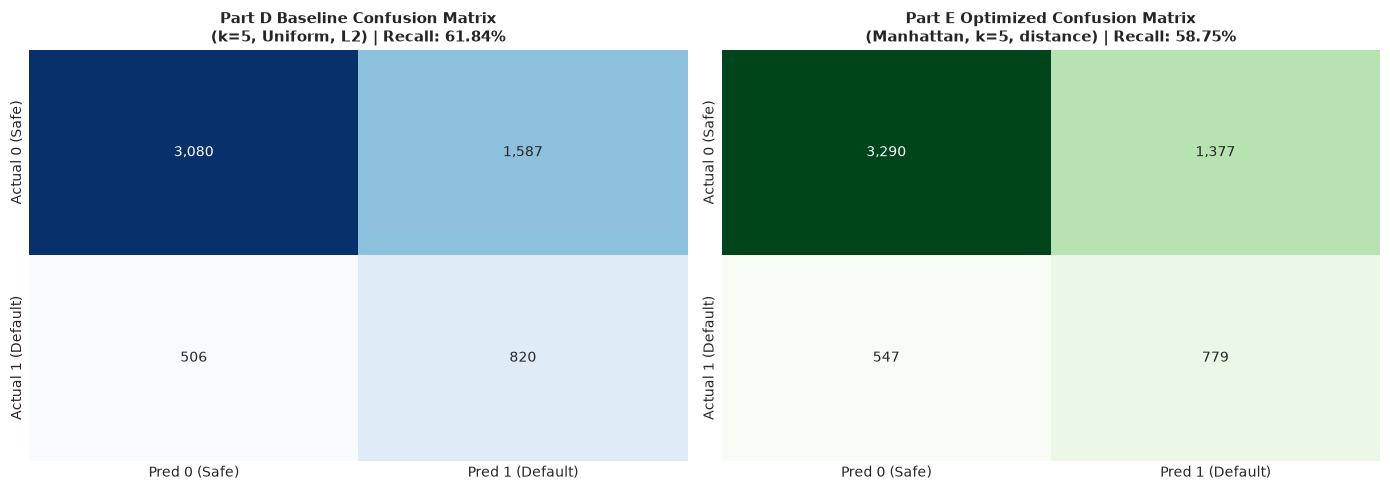

In [8]:
# Retrieve best estimator
best_knn = grid_search.best_estimator_

# Profile training and inference latency
start_opt_train = time.time()
best_knn.fit(X_train, y_train)
opt_train_time = time.time() - start_opt_train

start_opt_infer = time.time()
opt_preds = best_knn.predict(X_test)
opt_probs = best_knn.predict_proba(X_test)[:, 1]
opt_infer_time = time.time() - start_opt_infer

# Compute test metrics
opt_acc = accuracy_score(y_test, opt_preds)
opt_prec = precision_score(y_test, opt_preds)
opt_rec = recall_score(y_test, opt_preds)
opt_f1 = f1_score(y_test, opt_preds)
opt_auc = roc_auc_score(y_test, opt_probs)

# Plot Confusion Matrices Side-by-Side: Baseline vs. Optimized
cm_base = confusion_matrix(y_test, base_preds)
cm_opt = confusion_matrix(y_test, opt_preds)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(cm_base, annot=True, fmt=',d', cmap='Blues', ax=axes[0], cbar=False,
            xticklabels=['Pred 0 (Safe)', 'Pred 1 (Default)'],
            yticklabels=['Actual 0 (Safe)', 'Actual 1 (Default)'])
axes[0].set_title(f"Part D Baseline Confusion Matrix\n(k=5, Uniform, L2) | Recall: {base_rec*100:.2f}%", fontsize=11, weight='bold')

sns.heatmap(cm_opt, annot=True, fmt=',d', cmap='Greens', ax=axes[1], cbar=False,
            xticklabels=['Pred 0 (Safe)', 'Pred 1 (Default)'],
            yticklabels=['Actual 0 (Safe)', 'Actual 1 (Default)'])
axes[1].set_title(f"Part E Optimized Confusion Matrix\n({grid_search.best_params_['metric'].capitalize()}, k={grid_search.best_params_['n_neighbors']}, {grid_search.best_params_['weights']}) | Recall: {opt_rec*100:.2f}%", fontsize=11, weight='bold')

plt.tight_layout()
plt.show()

print("\n=== OPTIMIZED KNN CLASSIFICATION REPORT ===")
print(classification_report(y_test, opt_preds, target_names=['Safe Account (0)', 'Default Account (1)'], digits=4))

## 8. Direct Comparative Analysis: Baseline (Part D) vs. Optimized (Part E)


=== MASTER PERFORMANCE COMPARISON: BASELINE (PART D) VS. OPTIMIZED (PART E) ===


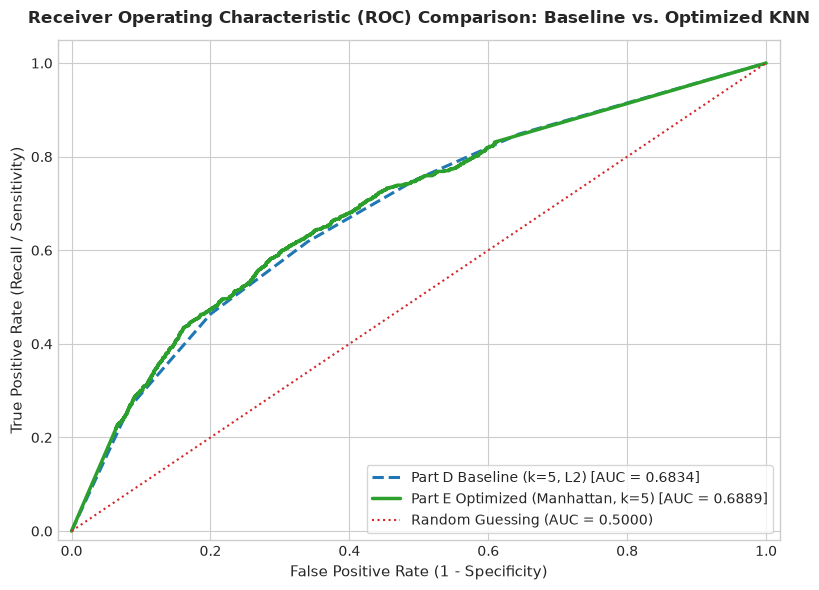

,Metric,Part D Baseline,Part E Optimized,Absolute Change (Δ),Relative Impact (%)
0,Model Configuration,"k=5, Uniform, Euclidean (L2)","k=5, Distance, Manhattan",Hyperparameter Shift,Optimized via CV
1,Accuracy,0.6508,0.6790,+0.0282,+4.33%
2,Precision (Default),0.3407,0.3613,+0.0206,+6.06%
3,Recall / Sensitivity (Default),0.6184,0.5875,-0.0309,-5.00%
4,F1-Score,0.4393,0.4474,+0.0081,+1.85%
5,ROC-AUC Score,0.6834,0.6889,+0.0055,+0.80%
6,Fit Latency (s),0.1235,0.0086,-0.1149,-93.03%
7,Inference Latency (s),0.7576,1.7905,+1.0330,+136.35%
8,True Positives (Defaults Caught),820,779,-41,-5.00%
9,False Negatives (Missed Defaults),506,547,+41,+8.10%


In [9]:
# Compute comparative summary table
comparison_df = pd.DataFrame({
    'Metric': [
        'Model Configuration',
        'Accuracy',
        'Precision (Default)',
        'Recall / Sensitivity (Default)',
        'F1-Score',
        'ROC-AUC Score',
        'Fit Latency (s)',
        'Inference Latency (s)',
        'True Positives (Defaults Caught)',
        'False Negatives (Missed Defaults)',
        'False Positives (False Alarms)'
    ],
    'Part D Baseline': [
        'k=5, Uniform, Euclidean (L2)',
        f"{base_acc:.4f}",
        f"{base_prec:.4f}",
        f"{base_rec:.4f}",
        f"{base_f1:.4f}",
        f"{base_auc:.4f}",
        f"{base_train_time:.4f}",
        f"{base_infer_time:.4f}",
        f"{cm_base[1, 1]:,}",
        f"{cm_base[1, 0]:,}",
        f"{cm_base[0, 1]:,}"
    ],
    'Part E Optimized': [
        f"k={grid_search.best_params_['n_neighbors']}, {grid_search.best_params_['weights'].capitalize()}, {grid_search.best_params_['metric'].capitalize()}",
        f"{opt_acc:.4f}",
        f"{opt_prec:.4f}",
        f"{opt_rec:.4f}",
        f"{opt_f1:.4f}",
        f"{opt_auc:.4f}",
        f"{opt_train_time:.4f}",
        f"{opt_infer_time:.4f}",
        f"{cm_opt[1, 1]:,}",
        f"{cm_opt[1, 0]:,}",
        f"{cm_opt[0, 1]:,}"
    ],
    'Absolute Change (Δ)': [
        'Hyperparameter Shift',
        f"{opt_acc - base_acc:+.4f}",
        f"{opt_prec - base_prec:+.4f}",
        f"{opt_rec - base_rec:+.4f}",
        f"{opt_f1 - base_f1:+.4f}",
        f"{opt_auc - base_auc:+.4f}",
        f"{opt_train_time - base_train_time:+.4f}",
        f"{opt_infer_time - base_infer_time:+.4f}",
        f"{cm_opt[1, 1] - cm_base[1, 1]:+d}",
        f"{cm_opt[1, 0] - cm_base[1, 0]:+d}",
        f"{cm_opt[0, 1] - cm_base[0, 1]:+d}"
    ],
    'Relative Impact (%)': [
        'Optimized via CV',
        f"{((opt_acc - base_acc) / base_acc) * 100:+.2f}%",
        f"{((opt_prec - base_prec) / base_prec) * 100:+.2f}%",
        f"{((opt_rec - base_rec) / base_rec) * 100:+.2f}%",
        f"{((opt_f1 - base_f1) / base_f1) * 100:+.2f}%",
        f"{((opt_auc - base_auc) / base_auc) * 100:+.2f}%",
        f"{((opt_train_time - base_train_time) / base_train_time) * 100:+.2f}%",
        f"{((opt_infer_time - base_infer_time) / base_infer_time) * 100:+.2f}%",
        f"{((cm_opt[1, 1] - cm_base[1, 1]) / cm_base[1, 1]) * 100:+.2f}%",
        f"{((cm_opt[1, 0] - cm_base[1, 0]) / cm_base[1, 0]) * 100:+.2f}%",
        f"{((cm_opt[0, 1] - cm_base[0, 1]) / cm_base[0, 1]) * 100:+.2f}%"
    ]
})

print("=== MASTER PERFORMANCE COMPARISON: BASELINE (PART D) VS. OPTIMIZED (PART E) ===")
display(comparison_df)

# Plot Overlay ROC Curves
fpr_base, tpr_base, _ = roc_curve(y_test, base_probs)
fpr_opt, tpr_opt, _ = roc_curve(y_test, opt_probs)

fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(fpr_base, tpr_base, color='#1f77b4', lw=2.2, linestyle='--',
        label=f"Part D Baseline (k=5, L2) [AUC = {base_auc:.4f}]")
ax.plot(fpr_opt, tpr_opt, color='#2ca02c', lw=2.5,
        label=f"Part E Optimized ({grid_search.best_params_['metric'].capitalize()}, k={grid_search.best_params_['n_neighbors']}) [AUC = {opt_auc:.4f}]")
ax.plot([0, 1], [0, 1], color='#d62728', lw=1.5, linestyle=':', label='Random Guessing (AUC = 0.5000)')

ax.set_xlim([-0.02, 1.02])
ax.set_ylim([-0.02, 1.05])
ax.set_xlabel('False Positive Rate (1 - Specificity)', fontsize=11)
ax.set_ylabel('True Positive Rate (Recall / Sensitivity)', fontsize=11)
ax.set_title('Receiver Operating Characteristic (ROC) Comparison: Baseline vs. Optimized KNN', fontsize=12, weight='bold', pad=12)
ax.legend(loc='lower right', frameon=True, fontsize=10)
plt.tight_layout()
plt.show()

## 9. Critical Technical Discussion & Latency Profiling


## 10. Final Summary Table & Export for Part F


In [10]:
# Create export dataframe for Part F
export_df = pd.DataFrame({
    'y_true': y_test,
    'knn_baseline_pred': base_preds,
    'knn_baseline_prob': base_probs,
    'knn_optimized_pred': opt_preds,
    'knn_optimized_prob': opt_probs
})

export_df.to_csv('knn_optimized_test_predictions.csv', index=False)
print("Part E Hyperparameter Optimization completed successfully.")
print(f"Exported {export_df.shape[0]:,} test predictions to 'knn_optimized_test_predictions.csv' for Part F Ensemble construction.")

Part E Hyperparameter Optimization completed successfully.
Exported 5,993 test predictions to 'knn_optimized_test_predictions.csv' for Part F Ensemble construction.
